# P2A burn and the 31.0.0 fleet: daily charts

Rebuilds two charts of the "P2A burn and the 31.0.0 fleet" dashboard:

1. **Reconstruction, suspicious agents and rejections per day**
2. **Messages received per day and peer group**

Two sources feed them:

- `data/daily_metrics.csv`: peer-observer metrics from Prometheus, one row per UTC day.
- `data/full_daily_msgs.csv`: one pass over every bitcoind `debug.log` (from Jul 8), counting the messages
  each peer sent and tying each peer to the user agent and protocol of its version message.

Both files ship with the notebook, through Oct 23 (cut at Oct 24 00:00 UTC), so the charts draw
without Prometheus or the logs. Set `REFRESH_PROMETHEUS` or `REBUILD_LOGPASS` to rebuild them from the
sources; the log pass reads ~100 large compressed logs and took about 1h45 on this machine.

Peer groups (user agent and protocol only, tx contents play no part):

| group | rule |
|---|---|
| p2aburn | user agent starts with `/p2aburn` |
| txbroadcast | user agent starts with `/txbroadcast` |
| fleet | `/Sat0shi:31.0.0/`, or `/Satoshi:31.0.0/` with protocol 70015 |
| other | everyone else |
| unknown | peers whose version message is in no log we have (connected before Jul 8); drawn with other |

In [1]:
import csv, datetime as dt, json, os, re, subprocess, urllib.parse, urllib.request
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

DATA = Path('data')
PROMETHEUS = 'http://localhost:9090'
PROM_START = '2026-05-02T00:00:00Z'
LOG_DIR = Path('/root/.bitcoin')
LOGPASS_CACHE = Path.home() / 'tmp' / 'p2a-logpass'
LOGPASS_FIRST = 'debug.log-2026-07-09T00:00Z'  # first rotated log kept; it holds Jul 8
LOGPASS_JOBS = 4
# the data in data/ ends here; move it forward to extend the charts
CUT = dt.datetime(2026, 10, 24, tzinfo=dt.timezone.utc)

REFRESH_PROMETHEUS = False
REBUILD_LOGPASS = False

EVENTS = [
    ('2026-07-04T17:26:00Z', 'txbroadcast', 'txbroadcast arrives'),
    ('2026-07-14T15:42:00Z', 'p2aburn', 'p2aburn arrives'),
    ('2026-07-25T20:19:00Z', 'txbroadcast', 'txbroadcast stops'),
    ('2026-07-28T14:17:00Z', 'fleet', 'fleet arrives'),
    ('2026-10-18T13:28:00Z', 'fleet', 'fleet stops'),
]

## Event lines

The dashed lines in both charts, in the color of the group they belong to. They came from the logs and the metrics while investigating:

- txbroadcast arrives Jul 4 17:26 (peer-observer metrics, before the first log we have) and stops Jul 25 20:19 (its last tx);
- p2aburn arrives Jul 14 15:42 (first `/p2aburn:1.0/` connection); it kept connecting after Oct 18, so it has no stop;
- the fleet arrives Jul 28 14:17 (first `/Sat0shi:31.0.0/` connection) and stops Oct 18 13:28 (it closes its connections).

## 1. Prometheus export

Each value is `increase(...[1d])` (or `max_over_time`) at midnight, so it covers the 24 hours before it and is
labeled with that calendar day. The last, partial day uses the window from 00:00 UTC to `CUT`.

In [2]:
PROM_QUERIES = {
    'reconstruction_no_request_share': 'sum(increase(peerobserver_log_compact_block_reconstruction_count{tx_requested="false"}[1d])) / sum(increase(peerobserver_log_compact_block_reconstruction_count[1d]))',
    'blocks_reconstructed': 'sum(increase(peerobserver_log_compact_block_reconstruction_count[1d]))',
    'p2aburn_connections': 'sum(increase(peerobserver_p2p_version_useragent{useragent=~"/p2aburn.*"}[1d]))',
    'sat0shi_connections': 'sum(increase(peerobserver_p2p_version_useragent{useragent="/Sat0shi:31.0.0/"}[1d]))',
    'rejected_inputs_missing': 'sum(increase(peerobserver_mempool_rejected{reason="bad-txns-inputs-missingorspent"}[1d]))',
    'rejected_insufficient_fee': 'sum(increase(peerobserver_mempool_rejected{reason="insufficient fee"}[1d]))',
}


def prom(path, **params):
    url = f'{PROMETHEUS}/api/v1/{path}?' + urllib.parse.urlencode(params)
    return json.load(urllib.request.urlopen(url))['data']['result']


def utc_day(ts):
    return dt.datetime.fromtimestamp(ts, dt.timezone.utc).strftime('%Y-%m-%d')


def prom_daily(expr, cut):
    """day -> value of expr over that day; the day CUT falls in covers only 00:00 to CUT."""
    cut_ts = int(cut.timestamp())
    midnight = cut_ts - cut_ts % 86400
    result = prom('query_range', query=expr, start=PROM_START, end=str(midnight), step='1d')
    # a sample at midnight covers the day before it
    out = {utc_day(ts - 86400): float(v) for ts, v in (result[0]['values'] if result else [])}
    if cut_ts > midnight:
        result = prom('query', query=expr.replace('[1d]', f'[{cut_ts - midnight}s]'), time=str(cut_ts))
        if result:
            out[utc_day(midnight)] = float(result[0]['value'][1])
    return out


def export_daily_metrics(dest, cut):
    data = {name: prom_daily(expr, cut) for name, expr in PROM_QUERIES.items()}
    days = sorted(d for d in set().union(*data.values()) if d >= '2026-05-01')
    with open(dest, 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['day', *PROM_QUERIES])
        for d in days:
            row = [d]
            for name in PROM_QUERIES:
                v = data[name].get(d)
                if v is None:
                    row.append('')
                elif name.startswith('reconstruction'):  # a share; the rest are counts
                    row.append(round(v, 4))
                else:
                    row.append(round(v))
            w.writerow(row)
    return len(days), days[0], days[-1]


if REFRESH_PROMETHEUS:
    print(export_daily_metrics(DATA / 'daily_metrics.csv', CUT))

## 2. Log pass

Per log file: `zstdcat | grep | awk` keeps the `received:`, `sending getdata`, version-message and startup lines,
and counts messages and bytes per (bitcoind run, hour, peer, message type). Peer ids restart at every bitcoind
start, so the awk numbers each run inside a file (`seg`), and the join forgets every peer id when a new run starts.
Lines at or after `CUT` are dropped.

Each rotated file's counts are cached under `LOGPASS_CACHE/<cut>/`, so an interrupted pass resumes where it
stopped; the live `debug.log` is counted again on every run. If logrotate runs during the pass, the cell stops and
asks to be run again.
The join then walks the files in time order, carrying each peer id's user agent across files.

In [3]:
# Output lines: segment, hour (YYYY-MM-DDTHH), peer=<id>, message type, count, bytes; sent getdatas are counted
# as type "getdata_sent", with no bytes. Version-message lines go to the VER file, prefixed with their segment.
PEERHOUR_AWK = r"""
BEGIN { seg = 0; OFS = "\t" }
$1 >= CUT { exit }
$3 == "received:" { k = seg SUBSEP substr($1, 1, 13) SUBSEP $NF SUBSEP $4; c[k]++; b[k] += substr($5, 2); next }
$3 == "sending" && $4 == "getdata" { k = seg SUBSEP substr($1, 1, 13) SUBSEP $NF SUBSEP "getdata_sent"; c[k]++; next }
/Bitcoin Core version v/ { seg++; next }
/receive version message: / { print seg, $0 > VER }
END { for (k in c) { split(k, a, SUBSEP); print a[1], a[2], a[3], a[4], c[k], b[k] } }
"""
GREP_KEYS = ['] received: ', 'sending getdata', 'receive version message: ', 'Bitcoin Core version v']


def log_files():
    rotated = sorted(p for p in (LOG_DIR / 'logs-rotated').glob('debug.log-*') if p.name >= LOGPASS_FIRST)
    return rotated + [LOG_DIR / 'debug.log']


def count_file(path, cache, cut):
    cnt, ver = cache / (path.name + '.cnt'), cache / (path.name + '.ver')
    # the live log changes between runs, and after a rotation its old lines are in a rotated file
    if path.name != 'debug.log' and cnt.exists() and ver.exists():
        return path.name, 'cached'
    decompress = 'zstdcat' if path.suffix == '.zst' else 'cat'
    greps = ' '.join(f"-e '{k}'" for k in GREP_KEYS)
    # the live log keeps growing; read only the bytes it has now
    cmd = (f"head -c {path.stat().st_size} '{path}' | nice -n 19 {decompress}"
           f" | LC_ALL=C nice -n 19 grep -a -F {greps}"
           f" | LC_ALL=C nice -n 19 awk -v CUT='{cut:%Y-%m-%dT%H:%M}' -v VER='{ver}.tmp' -f '{cache / 'peerhour.awk'}'"
           f" > '{cnt}.tmp'; echo \"${{PIPESTATUS[*]}}\"")
    run = subprocess.run(['ionice', '-c3', 'bash', '-c', cmd], capture_output=True, text=True)
    head, unpack, grep, awk = map(int, run.stdout.split())
    # awk stops reading at CUT, so the stages before it may die of SIGPIPE (141); grep exits 1 on no match
    if awk != 0 or head not in (0, 141) or unpack not in (0, 141) or grep not in (0, 1, 141):
        Path(f'{cnt}.tmp').unlink(missing_ok=True)
        Path(f'{ver}.tmp').unlink(missing_ok=True)
        raise RuntimeError(f'{path.name}: pipeline failed (exit codes: {head} {unpack} {grep} {awk}) {run.stderr.strip()}')
    # awk creates the .ver only when the log has a version message
    Path(f'{ver}.tmp').touch()
    os.replace(f'{ver}.tmp', ver)
    os.replace(f'{cnt}.tmp', cnt)
    return path.name, 'done'


def run_logpass(cut):
    """Counts every log into the cache for this cut; returns their (cnt, ver) paths in time order."""
    cache = LOGPASS_CACHE / f'{cut:%Y%m%dT%H%M}'
    cache.mkdir(parents=True, exist_ok=True)
    (cache / 'peerhour.awk').write_text(PEERHOUR_AWK)
    files = log_files()
    try:
        with ThreadPoolExecutor(LOGPASS_JOBS) as pool:
            for name, status in pool.map(lambda p: count_file(p, cache, cut), files):
                print(name, status, flush=True)
    finally:
        if log_files() != files:
            raise RuntimeError('debug.log was rotated during the pass; run this cell again')
    return [(cache / (p.name + '.cnt'), cache / (p.name + '.ver')) for p in files]

In [4]:
VERSION_RX = re.compile(r'receive version message: (.*): version (\d+), .*peer=(\d+)$')
GROUPS = ['p2aburn', 'fleet', 'txbroadcast', 'other', 'unknown']


def peer_group(ua, protocol):
    if ua.startswith('/p2aburn'):
        return 'p2aburn'
    if ua.startswith('/txbroadcast'):
        return 'txbroadcast'
    if ua == '/Sat0shi:31.0.0/' or (ua == '/Satoshi:31.0.0/' and protocol == '70015'):
        return 'fleet'
    return 'other'


def join_counts(pairs):
    """pairs: (cnt, ver) per log file, in time order -> rows of full_daily_msgs.csv."""
    peers = {}  # peer id -> group
    totals = defaultdict(Counter)  # (day, group) -> Counter over the CSV columns
    day_peers = defaultdict(set)  # (day, group) -> peer ids
    for cnt_path, ver_path in pairs:
        versions = defaultdict(list)  # segment -> [(day, ua, protocol, peer id)]
        with open(ver_path, errors='replace') as f:
            for line in f:
                segment, text = line.rstrip('\n').split('\t', 1)
                m = VERSION_RX.search(text)
                if m:
                    versions[int(segment)].append((text[:10], *m.groups()))
        counts = defaultdict(list)  # segment -> [(hour, peer id, msg, count, bytes)]
        with open(cnt_path, errors='replace') as f:
            for line in f:
                segment, hour, peer, msg, count, nbytes = line.rstrip('\n').split('\t')
                counts[int(segment)].append((hour, peer[len('peer='):], msg, int(count), int(nbytes or 0)))
        for segment in sorted(set(versions) | set(counts)):
            if segment > 0:
                peers = {}
            for day, ua, protocol, peer in versions[segment]:
                group = peer_group(ua, protocol)
                peers[peer] = group
                if group != 'other':
                    totals[(day, group)]['new_connections'] += 1
            for hour, peer, msg, count, nbytes in counts[segment]:
                group = peers.get(peer, 'unknown')
                if msg == 'version' and group == 'unknown':
                    continue
                t = totals[(hour[:10], group)]
                if msg == 'getdata_sent':
                    t['getdata_sent'] += count
                else:
                    t['messages'] += count
                    if msg == 'tx':
                        t['tx'] += count
                        t['tx_bytes'] += nbytes
                day_peers[(hour[:10], group)].add(peer)
    columns = ['tx', 'messages', 'tx_bytes', 'getdata_sent', 'new_connections', 'distinct_peers']
    rows = []
    for day in sorted({d for d, _ in totals}):
        for group in GROUPS:
            t = totals.get((day, group), Counter())
            if group == 'unknown' and not t:
                continue
            t['distinct_peers'] = len(day_peers.get((day, group), ()))
            rows.append([day, group] + [t[c] for c in columns])
    return ['day', 'group'] + columns, rows


if REBUILD_LOGPASS:
    header, rows = join_counts(run_logpass(CUT))
    with open(DATA / 'full_daily_msgs.csv', 'w', newline='') as f:
        csv.writer(f).writerows([header, *rows])
    print(len(rows), 'rows', rows[0][0], rows[-1][0])

## 3. Load

In [5]:
metrics = pd.read_csv(DATA / 'daily_metrics.csv', parse_dates=['day'])
msgs = pd.read_csv(DATA / 'full_daily_msgs.csv', parse_dates=['day'])
print(f'daily_metrics: {len(metrics)} days, {metrics.day.min():%b %-d} to {metrics.day.max():%b %-d}')
print(f'full_daily_msgs: {msgs.day.nunique()} days, {msgs.day.min():%b %-d} to {msgs.day.max():%b %-d}')

# new and active connections per group, empty on days with no logs
conn = msgs.pivot_table(index='day', columns='group', values=['new_connections', 'distinct_peers'], aggfunc='sum')
panels = metrics[['day', 'reconstruction_no_request_share', 'rejected_inputs_missing']].set_index('day')
for g in ['txbroadcast', 'fleet', 'p2aburn']:
    panels[f'{g}_new'] = conn[('new_connections', g)].reindex(panels.index)
    panels[f'{g}_active'] = conn[('distinct_peers', g)].reindex(panels.index)
# a sample of the table the first chart draws: p2aburn's first days, up to txbroadcast's stop
panels.loc['2026-07-15':'2026-07-26']

daily_metrics: 173 days, May 4 to Oct 23
full_daily_msgs: 108 days, Jul 8 to Oct 23


,reconstruction_no_request_share,rejected_inputs_missing,txbroadcast_new,txbroadcast_active,fleet_new,fleet_active,p2aburn_new,p2aburn_active
day,,,,,,,,
2026-07-15,0.3714,90416,23.0,24.0,0.0,0.0,5.0,5.0
2026-07-16,0.3967,44781,6.0,7.0,0.0,0.0,0.0,0.0
2026-07-17,0.4488,66939,8.0,9.0,0.0,0.0,0.0,0.0
2026-07-18,0.2771,291256,66.0,67.0,0.0,0.0,15.0,15.0
2026-07-19,0.1515,374069,68.0,69.0,0.0,0.0,0.0,0.0
2026-07-20,0.2055,277164,58.0,59.0,0.0,0.0,17.0,17.0
2026-07-21,0.2536,70022,13.0,14.0,0.0,0.0,30.0,30.0
2026-07-22,0.1304,147956,25.0,26.0,0.0,0.0,52.0,52.0
2026-07-23,0.0451,464720,91.0,92.0,0.0,0.0,104.0,106.0


## 4. Chart style

Each peer group keeps one color in both charts; the reconstruction line is neutral so no group color means two things. Each panel keeps its own y scale; all share the date axis.

In [6]:
COLORS = {
    'share': '#3d3c38',
    'missing': '#eda100',
    'p2aburn': '#2a78d6',
    'fleet': '#eb6834',
    'txbroadcast': '#1baf7a',
    'other': '#8a8a85',
}
LABELS = {
    'p2aburn': '/p2aburn:1.0/',
    'fleet': 'fleet (31.0.0/70015)',
    'txbroadcast': '/txbroadcast:0.1/',
    'other': 'other peers',
}
INK, MUTED, GRID, AXIS = '#1f1e1d', '#6b6a64', '#e6e5e0', '#a9a8a2'
ONE_DAY = pd.Timedelta(days=1)

plt.rcParams.update({
    'font.size': 9, 'axes.titlesize': 9, 'axes.titlelocation': 'left', 'axes.titlecolor': INK,
    'axes.edgecolor': AXIS, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID, 'grid.linewidth': 0.8,
    'ytick.left': False, 'figure.dpi': 110, 'hatch.linewidth': 1.0,
})
events = [(pd.Timestamp(t).tz_localize(None), group, label) for t, group, label in EVENTS]


def compact(v, _=None):
    for div, suffix in ((1e9, 'B'), (1e6, 'M'), (1e3, 'K')):
        if abs(v) >= div:
            return f'{v / div:.1f}'.rstrip('0').rstrip('.') + suffix
    return f'{v:g}'


def percent(v, _=None):
    return f'{v:.0%}'


def style_axis(ax, x0, x1, fmt=compact):
    ax.set_xlim(x0, x1)
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_locator(plt.MaxNLocator(3))
    ax.yaxis.set_major_formatter(fmt)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %-d'))
    ax.set_axisbelow(True)
    for t, group, _ in events:
        if x0 <= t <= x1:
            ax.axvline(t, color=COLORS[group], lw=1.1, ls=(0, (4, 3)), zorder=0)


def panel_figure(n, height):
    """A strip for the event labels above n panels sharing the date axis."""
    fig, axes = plt.subplots(n + 1, 1, figsize=(12, height), sharex=True,
                             gridspec_kw={'hspace': 0.45, 'height_ratios': [0.55] + [1] * n})
    strip = axes[0]
    strip.axis('off')
    return fig, strip, axes[1:]


def label_events(strip, x0, x1):
    """One row per event, earliest at the top, each label beside its line."""
    shown = [(t, group, label) for t, group, label in events if x0 <= t <= x1]
    strip.set_ylim(0, len(shown) or 1)
    for i, (t, group, label) in enumerate(shown):
        row = len(shown) - 1 - i
        strip.vlines(t, 0, row + 0.5, color=COLORS[group], lw=1.1, ls=(0, (4, 3)))
        # the last event sits near the right edge, so its label goes to the left of its line
        last = i == len(shown) - 1
        strip.text(t, row + 0.5, ('' if last else ' ') + label + (' ' if last else ''), ha='right' if last else 'left',
                   va='center', color=MUTED, fontsize=8)

## 5. Reconstruction, suspicious agents and rejections per day

Top two panels: peer-observer metrics. Bottom three: the log pass, so they start on Jul 8. A connection counts on
the day its version message arrives.

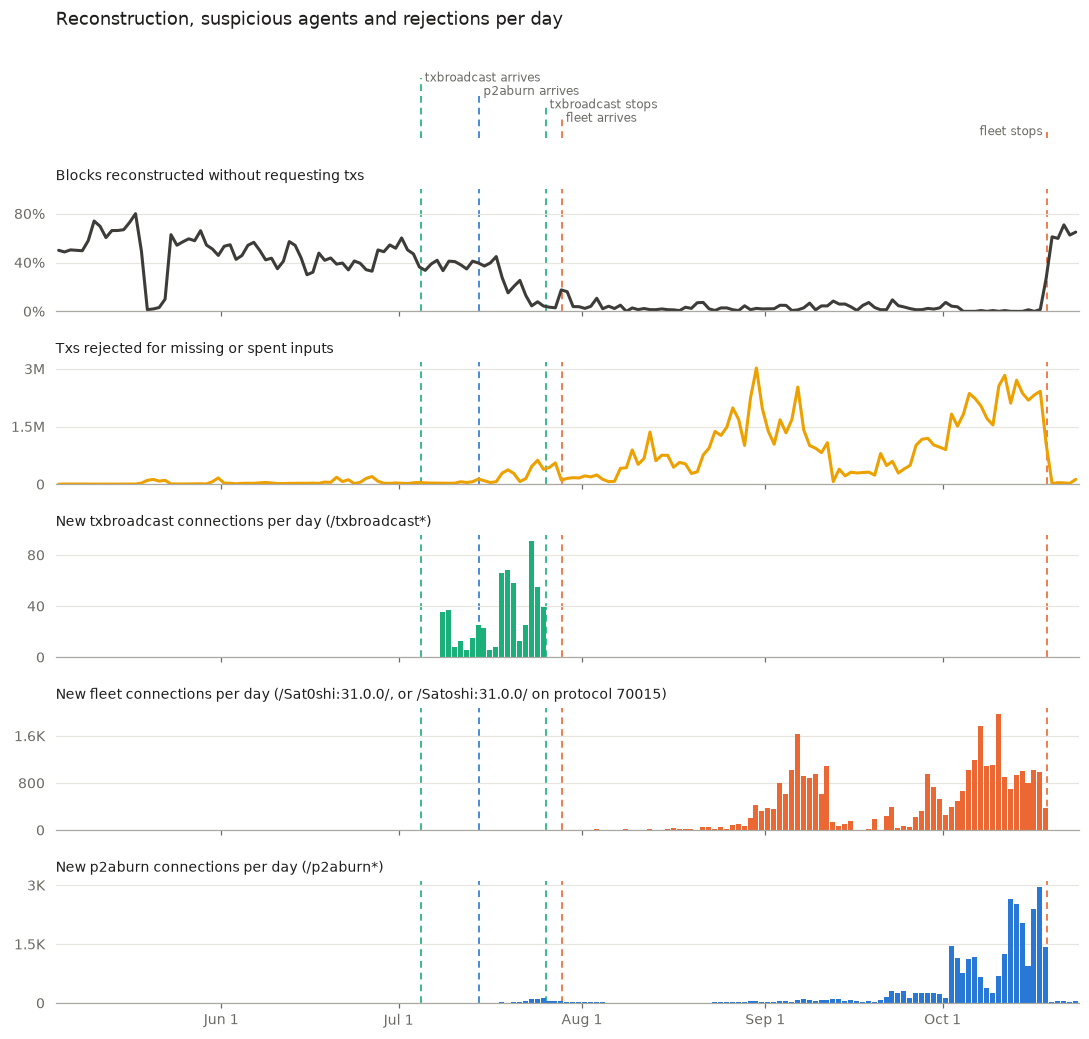

In [7]:
x0, x1 = panels.index.min(), panels.index.max() + ONE_DAY
noon = panels.index + ONE_DAY / 2  # a day's value is drawn at noon, over that day's bar
panel_specs = [
    ('Blocks reconstructed without requesting txs', 'line', 'reconstruction_no_request_share', COLORS['share']),
    ('Txs rejected for missing or spent inputs', 'line', 'rejected_inputs_missing', COLORS['missing']),
    ('New txbroadcast connections per day (/txbroadcast*)', 'bar', 'txbroadcast_new', COLORS['txbroadcast']),
    ('New fleet connections per day (/Sat0shi:31.0.0/, or /Satoshi:31.0.0/ on protocol 70015)', 'bar', 'fleet_new', COLORS['fleet']),
    ('New p2aburn connections per day (/p2aburn*)', 'bar', 'p2aburn_new', COLORS['p2aburn']),
]
fig, strip, axes = panel_figure(len(panel_specs), 11)
for ax, (title, kind, column, color) in zip(axes, panel_specs):
    series = panels[column]
    if kind == 'line':
        ax.plot(noon, series, color=color, lw=2, solid_joinstyle='round', solid_capstyle='round')
    else:
        series = series[series > 0]
        ax.bar(series.index, series, width=0.85, align='edge', color=color, lw=0)
    style_axis(ax, x0, x1, percent if column.endswith('share') else compact)
    ax.set_title(title)
axes[0].set_ylim(0, 1)
label_events(strip, x0, x1)
fig.suptitle('Reconstruction, suspicious agents and rejections per day', x=0.125, y=0.93, ha='left', fontsize=12, color=INK)
plt.show()

## 6. Messages received per day and peer group

The top panel repeats the reconstruction share from the first chart, on this chart's dates.

Solid: tx messages. Hatched on top (txbroadcast, p2aburn and fleet): every other message type. Other peers show tx
messages only, since about 90% of their traffic is other types and would flatten their tx bars. Until the Jul 28
restart, connections opened before Jul 8 have no user agent (`unknown`) and are drawn with other peers.

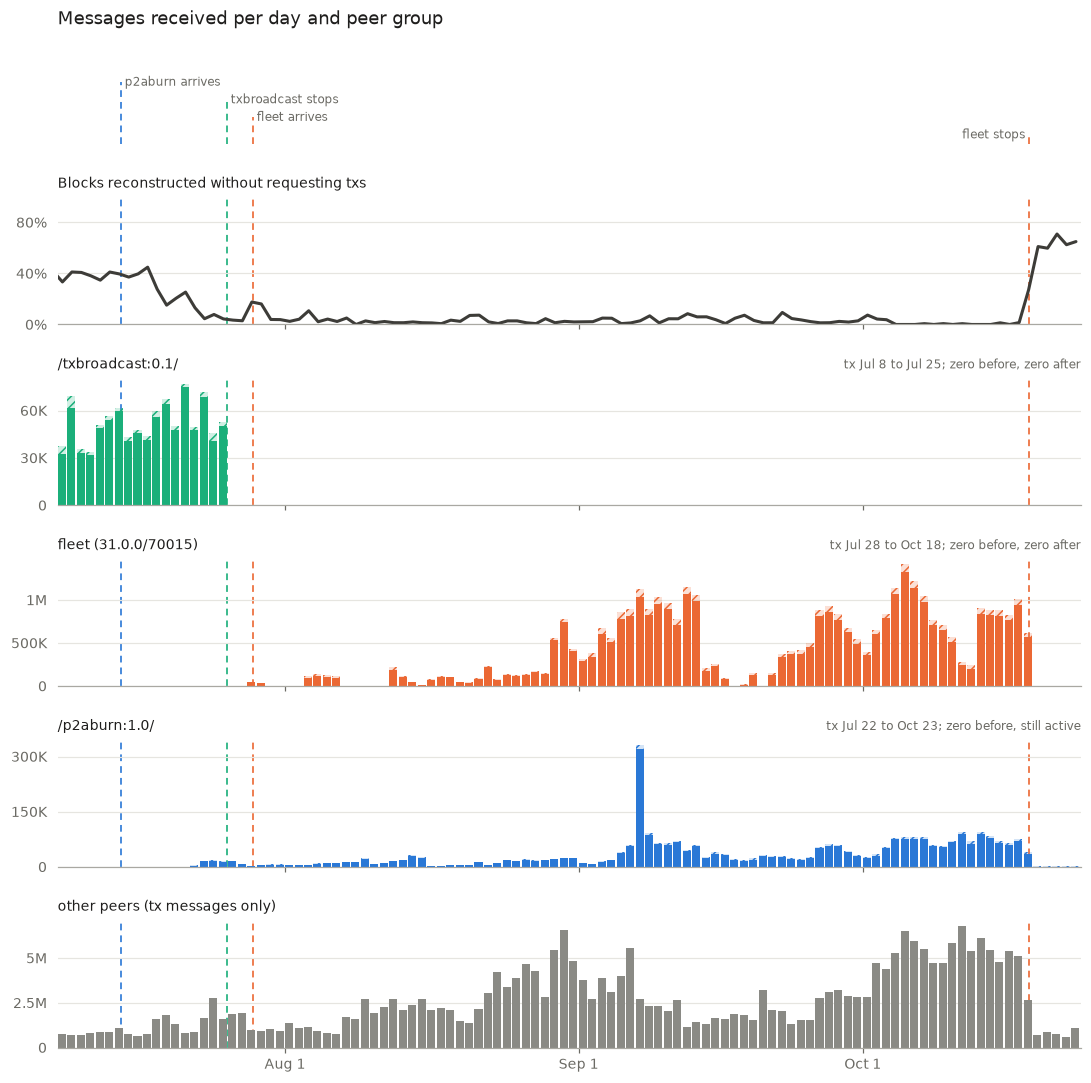

In [8]:
by_panel = msgs.assign(panel=msgs.group.replace({'unknown': 'other'}))
tx = by_panel.pivot_table(index='day', columns='panel', values='tx', aggfunc='sum').fillna(0)
all_msgs = by_panel.pivot_table(index='day', columns='panel', values='messages', aggfunc='sum').fillna(0)
x0, x1 = tx.index.min(), tx.index.max() + ONE_DAY
groups = ['txbroadcast', 'fleet', 'p2aburn', 'other']
fig, strip, axes = panel_figure(len(groups) + 1, 11.5)
share = panels['reconstruction_no_request_share']
axes[0].plot(share.index + ONE_DAY / 2, share, color=COLORS['share'], lw=2, solid_joinstyle='round', solid_capstyle='round')
style_axis(axes[0], x0, x1, percent)
axes[0].set_ylim(0, 1)
axes[0].set_title('Blocks reconstructed without requesting txs')
for ax, g in zip(axes[1:], groups):
    g_tx, g_all = tx[g], all_msgs[g]
    stacked = g != 'other'
    ax.bar(g_tx.index, g_tx, width=0.85, align='edge', color=COLORS[g], lw=0)
    if stacked:
        non_tx = (g_all - g_tx)[g_all > g_tx]
        ax.bar(non_tx.index, non_tx, bottom=g_tx[non_tx.index], width=0.85, align='edge', facecolor=COLORS[g] + '33',
               edgecolor=COLORS[g], hatch='////', lw=0)
    style_axis(ax, x0, x1)
    ax.set_title(LABELS[g] + ('' if stacked else ' (tx messages only)'))
    tx_days = g_tx[g_tx > 0]
    if stacked and len(tx_days):
        first, last = tx_days.index[0], tx_days.index[-1]
        after = 'still active' if last == g_tx.index[-1] else 'zero after'
        ax.set_title(f'tx {first:%b %-d} to {last:%b %-d}; zero before, {after}', loc='right', color=MUTED, fontsize=8)
label_events(strip, x0, x1)
fig.suptitle('Messages received per day and peer group', x=0.125, y=0.93, ha='left', fontsize=12, color=INK)
plt.show()